# Siren vs. Non-Siren Sound Classification Using a CNN

## Problem statement
Build a small Convolutional Neural Network (CNN) that classifies short urban audio recordings into two categories:

- **Siren (1)**
- **Non-siren (0)**

A CNN normally learns from images. Here, we first convert each audio clip into a **mel-spectrogram**—an image-like representation of sound over time and frequency—then train the CNN on these images.

**Dataset:** [UrbanSound8K](https://urbansounddataset.weebly.com/urbansound8k.html), loaded with [Soundata](https://github.com/soundata/soundata). Its official labels include `siren` as one of 10 classes.

**Run this notebook in Google Colab.** The dataset download is large and can take time. The notebook uses a small balanced subset so the model is easier to train and understand. It does not include the dataset files.

## 1. Install the libraries

Run this cell once. If Colab asks to restart the runtime after installation, do so and then continue from the imports.

In [1]:
!pip -q install soundata librosa scikit-learn matplotlib pandas tensorflow
!pip install tensorflow

## 2. Import the libraries

We use pandas to read the dataset labels, librosa to convert audio into spectrograms, and TensorFlow/Keras to build the CNN.

In [2]:
import sys

print(sys.version)
print(sys.executable)

%pip show tensorflow


3.10.20 | packaged by Anaconda, Inc. | (main, Jun 11 2026, 15:13:20) [MSC v.1942 64 bit (AMD64)]
C:\Users\ratna\anaconda3\envs\tf_env\python.exe


Name: tensorflow
Version: 2.21.0
Summary: TensorFlow is an open source machine learning framework for everyone.
Home-page: https://www.tensorflow.org/
Author: Google Inc.
Author-email: packages@tensorflow.org
License: Apache 2.0
Location: c:\users\ratna\anaconda3\envs\tf_env\lib\site-packages
Requires: absl-py, astunparse, flatbuffers, gast, google_pasta, grpcio, h5py, keras, libclang, ml_dtypes, numpy, opt_einsum, packaging, protobuf, requests, setuptools, six, termcolor, typing_extensions, wrapt
Required-by: 
Note: you may need to restart the kernel to use updated packages.


In [3]:
!pip install librosa

In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import librosa.display
import soundata
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from tensorflow.keras import layers, models

np.random.seed(42)
tf.random.set_seed(42)

## 3. Download and check UrbanSound8K

Soundata's documented workflow is to initialize the dataset, download it, and validate the expected files. If you already downloaded it to this same environment, Soundata can reuse the local copy.

In [5]:
dataset = soundata.initialize("urbansound8k")
dataset.download()

missing_files, invalid_files = dataset.validate(verbose=False)

# validate() returns {"metadata": ..., "clips": ...}; count the files inside.
missing_count = sum(len(files) for files in missing_files.values())
invalid_count = sum(len(files) for files in invalid_files.values())

print("Dataset folder:", dataset.data_home)
print("Missing files:", missing_count)
print("Files with checksum problems:", invalid_count)

if missing_count or invalid_count:
    raise RuntimeError(
        "Dataset validation failed. Fix the download before continuing."
    )

INFO: Downloading ['all', 'index']. Index is being stored in C:\Users\ratna\anaconda3\envs\tf_env\Lib\site-packages\soundata\datasets\indexes, and the rest of files in /tmp\sound_datasets\urbansound8k


INFO: [all] downloading UrbanSound8K.tar.gz


INFO: /tmp\sound_datasets\urbansound8k\UrbanSound8K.tar.gz already exists and will not be downloaded. Rerun with force_overwrite=True to delete this file and force the download.


INFO: /tmp\sound_datasets\urbansound8k\audio already exists. Run with force_overwrite=True to download from scratch


INFO: /tmp\sound_datasets\urbansound8k\FREESOUNDCREDITS.txt already exists. Run with force_overwrite=True to download from scratch


...

 84%|████████▍ | 984k/1.14M [00:02<00:00, 601kB/s]

 91%|█████████ | 1.04M/1.14M [00:02<00:00, 607kB/s]

 98%|█████████▊| 1.12M/1.14M [00:03<00:00, 613kB/s]

1.15MB [00:03, 382kB/s]                            

Dataset folder: /tmp\sound_datasets\urbansound8k
Missing files: 0
Files with checksum problems: 0


If there are missing files or checksum problems, fix the download before moving on. Do not continue with an incomplete dataset.

## 4. Read the dataset metadata

The CSV tells us the filename, fold, numeric class ID, and text class name. Each recording belongs to one of 10 original sound classes.

In [6]:
csv_path = os.path.join(
    dataset.data_home, "metadata", "UrbanSound8K.csv"
)

metadata = pd.read_csv(csv_path)

print("Number of recordings:", len(metadata))
print("Metadata columns:", metadata.columns.tolist())
metadata.head()

Number of recordings: 8732
Metadata columns: ['slice_file_name', 'fsID', 'start', 'end', 'salience', 'fold', 'classID', 'class']


,slice_file_name,fsID,start,end,salience,fold,classID,class
0,100032-3-0-0.wav,100032,0.0,0.317551,1,5,3,dog_bark
1,100263-2-0-117.wav,100263,58.5,62.500000,1,5,2,children_playing
2,100263-2-0-121.wav,100263,60.5,64.500000,1,5,2,children_playing
3,100263-2-0-126.wav,100263,63.0,67.000000,1,5,2,children_playing
4,100263-2-0-137.wav,100263,68.5,72.500000,1,5,2,children_playing


In [7]:
print("Recordings per original class:")
print(metadata["class"].value_counts().sort_index())

Recordings per original class:
class
air_conditioner     1000
car_horn             429
children_playing    1000
dog_bark            1000
drilling            1000
engine_idling       1000
gun_shot             374
jackhammer          1000
siren                929
street_music        1000
Name: count, dtype: int64


## 5. Create the two labels

UrbanSound8K uses the class name `siren` for siren recordings. We label those as 1 and group all other sound types under non-siren (0).

In [8]:
metadata["target"] = (metadata["class"] == "siren").astype(int)

print("Non-siren recordings:", (metadata["target"] == 0).sum())
print("Siren recordings:", (metadata["target"] == 1).sum())

Non-siren recordings: 7803
Siren recordings: 929


## 6. Create train, validation, and test sets

The dataset is already organized into 10 folds. We use folds 1–9 to choose our training and validation examples, and keep fold 10 aside for testing. This avoids randomly mixing the same fold into both development and test data.

For a shorter run, this notebook uses 400 examples per class for development. The test subset is balanced using the smaller class count in fold 10.

### 6a. Separate the folds

We keep fold 10 for the final test set. The other nine folds are used to prepare the training and validation data.

In [9]:
train_pool = metadata[metadata["fold"] != 10]
test_pool = metadata[metadata["fold"] == 10]

print("Available training-pool clips:", len(train_pool))
print("Available test-fold clips:", len(test_pool))

Available training-pool clips: 7895
Available test-fold clips: 837


### 6b. Sample the training examples

We use the same number of siren and non-siren clips to keep the training data balanced. If the dataset contains fewer examples than requested, the code automatically uses the smaller available count.

In [10]:
train_counts = train_pool["target"].value_counts()

if 0 not in train_counts or 1 not in train_counts:
    raise ValueError("The training folds must contain both classes.")

SAMPLES_PER_CLASS = 400
available_train = min(int(train_counts[0]), int(train_counts[1]))
train_count = min(SAMPLES_PER_CLASS, available_train)

siren_train = train_pool[train_pool["target"] == 1].sample(
    n=train_count, random_state=42
)
other_train = train_pool[train_pool["target"] == 0].sample(
    n=train_count, random_state=42
)

train_data = pd.concat([siren_train, other_train])
train_data = train_data.sample(frac=1, random_state=42).reset_index(drop=True)

print("Sampled training pool:", len(train_data))

Sampled training pool: 800


### 6c. Create the training and validation sets

The validation set helps us check how the model is doing while it learns. It is kept separate from the training examples.

In [11]:
train_data, val_data = train_test_split(
    train_data,
    test_size=0.2,
    random_state=42,
    stratify=train_data["target"]
)

print("Training examples:", len(train_data))
print("Validation examples:", len(val_data))

Training examples: 640
Validation examples: 160


### 6d. Prepare a balanced test set

Fold 10 is not used during training or validation. We use an equal number of siren and non-siren recordings from this fold for testing.

In [12]:
test_counts = test_pool["target"].value_counts()

if 0 not in test_counts or 1 not in test_counts:
    raise ValueError("Fold 10 must contain both siren and non-siren examples.")

available_test = min(int(test_counts[0]), int(test_counts[1]))

siren_test = test_pool[test_pool["target"] == 1].sample(
    n=available_test, random_state=42
)
other_test = test_pool[test_pool["target"] == 0].sample(
    n=available_test, random_state=42
)

test_data = pd.concat([siren_test, other_test])
test_data = test_data.sample(frac=1, random_state=42).reset_index(drop=True)

print("Test examples:", len(test_data))

Test examples: 166


## 7. Set the audio and spectrogram sizes

All clips are converted to mono audio at the same sample rate and made exactly 4 seconds long. This makes every spectrogram the same size, which is required to train a CNN in batches.

In [13]:
SAMPLE_RATE = 22050
AUDIO_SECONDS = 4
SAMPLES = SAMPLE_RATE * AUDIO_SECONDS
N_MELS = 64
HOP_LENGTH = 512

## 8. Convert one audio clip into a spectrogram

The Soundata clip's `.audio` property returns the audio signal and its sample rate. We resample it, pad or trim to 4 seconds, then convert it to a mel-spectrogram.

In [14]:
def audio_to_spectrogram(clip_id):
    audio, original_rate = dataset.clip(clip_id).audio

    if original_rate != SAMPLE_RATE:
        audio = librosa.resample(
            audio,
            orig_sr=original_rate,
            target_sr=SAMPLE_RATE
        )

    audio = librosa.util.fix_length(audio, size=SAMPLES)

    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=SAMPLE_RATE,
        n_fft=1024,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS
    )

    mel_db = librosa.power_to_db(mel, ref=np.max)
    return mel_db

## 9. View an example spectrogram

This lets us see the kind of image that the CNN will learn from.

C:\Users\ratna\anaconda3\envs\tf_env\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


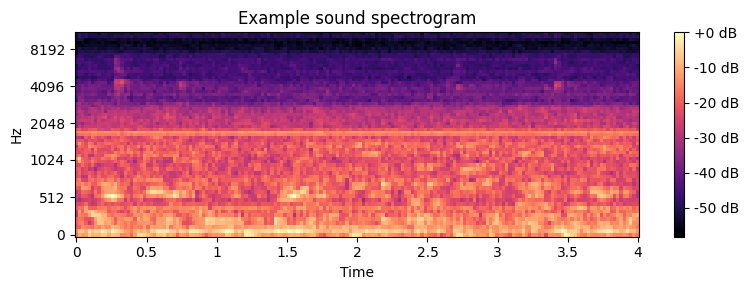

Actual class: non-siren


In [15]:
example_row = train_data.iloc[0]
example_clip_id = example_row["slice_file_name"].replace(".wav", "")

example_spectrogram = audio_to_spectrogram(example_clip_id)

plt.figure(figsize=(8, 3))
librosa.display.specshow(
    example_spectrogram,
    sr=SAMPLE_RATE,
    hop_length=HOP_LENGTH,
    x_axis="time",
    y_axis="mel"
)
plt.title("Example sound spectrogram")
plt.colorbar(format="%+2.0f dB")
plt.tight_layout()
plt.show()

print("Actual class:", "siren" if example_row["target"] == 1 else "non-siren")

## 10. Prepare the features and labels

This step reads each selected audio file and converts it into a spectrogram. If an individual file cannot be read, it prints a warning and skips that file.

In [16]:
def prepare_data(dataframe):
    features = []
    labels = []

    for _, row in dataframe.iterrows():
        clip_id = row["slice_file_name"].replace(".wav", "")

        try:
            spectrogram = audio_to_spectrogram(clip_id)
            features.append(spectrogram)
            labels.append(row["target"])
        except Exception as error:
            print("Could not read", row["slice_file_name"], "-", error)

    return np.array(features, dtype=np.float32), np.array(labels, dtype=np.float32)

Convert the three data splits. This may take a few minutes because every selected audio recording must be processed.

In [17]:
X_train, y_train = prepare_data(train_data)
X_val, y_val = prepare_data(val_data)
X_test, y_test = prepare_data(test_data)

print("Training feature shape:", X_train.shape)
print("Validation feature shape:", X_val.shape)
print("Test feature shape:", X_test.shape)

Training feature shape: (640, 64, 173)
Validation feature shape: (160, 64, 173)
Test feature shape: (166, 64, 173)


## 11. Scale the spectrograms

The spectrogram is measured in decibels. We scale the values to a range near 0–1 and add a final channel dimension because CNN image inputs have height, width, and channels.

In [18]:
def scale_features(features):
    features = ((features + 80) / 80).clip(0, 1)
    return features[..., np.newaxis]

X_train = scale_features(X_train)
X_val = scale_features(X_val)
X_test = scale_features(X_test)

print("CNN input shape:", X_train.shape[1:])

CNN input shape: (64, 173, 1)


## 12. Build the CNN

- `Conv2D` learns patterns in the spectrogram.
- `MaxPooling2D` reduces the size of the learned feature maps.
- `Flatten` turns the maps into a vector.
- The final sigmoid unit outputs a probability between 0 and 1.

In [19]:
model = models.Sequential([
    layers.Input(shape=X_train.shape[1:]),

    layers.Conv2D(8, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(16, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

In [20]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 173, 8)     │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 86, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 86, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 43, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 11008)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │       352,288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 353,569 (1.35 MB)

 Trainable params: 353,569 (1.35 MB)

 Non-trainable params: 0 (0.00 B)

## 13. Train the model

The model learns from the training examples and checks its performance on the validation set after each epoch. The test data is held back until evaluation.

In [21]:
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=8,
    batch_size=16
)

Epoch 1/8


 1/40 ━━━━━━━━━━━━━━━━━━━━ 2:49 4s/step - accuracy: 0.6875 - loss: 0.6733

 3/40 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.5764 - loss: 0.8932

 5/40 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.5546 - loss: 0.8757

 7/40 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.5411 - loss: 0.8542

...

34/40 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.8669 - loss: 0.2670

36/40 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.8669 - loss: 0.2680

38/40 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.8669 - loss: 0.2687

40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.8669 - loss: 0.2692

40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.8703 - loss: 0.2754 - val_accuracy: 0.9000 - val_loss: 0.2956


## 14. Plot training results

If training accuracy keeps rising while validation accuracy stops improving, the model may be overfitting.

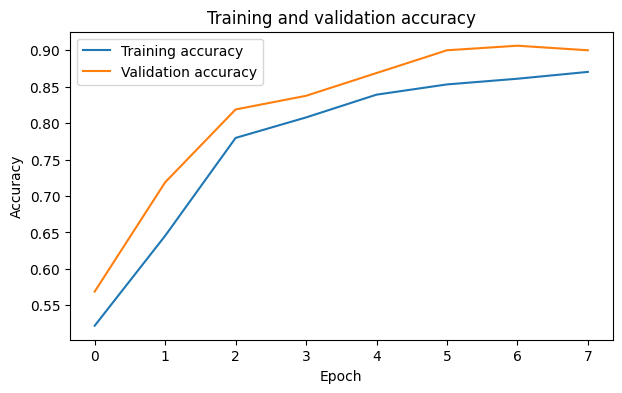

In [22]:
plt.figure(figsize=(7, 4))
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and validation accuracy")
plt.legend()
plt.show()

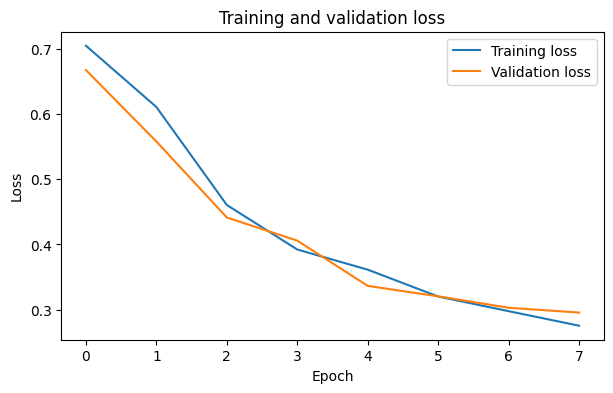

In [23]:
plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and validation loss")
plt.legend()
plt.show()

## 15. Evaluate on the test set

Accuracy is the percentage of correct predictions. Precision and recall help us understand how often siren predictions are correct and how many siren clips the model finds.

In [24]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)

print("Test loss:", round(test_loss, 4))
print("Test accuracy:", round(test_accuracy, 4))

Test loss: 0.933
Test accuracy: 0.6807


In [25]:
probabilities = model.predict(X_test, verbose=0).ravel()
predictions = (probabilities >= 0.5).astype(int)

print(classification_report(
    y_test.astype(int),
    predictions,
    labels=[0, 1],
    target_names=["non-siren", "siren"],
    zero_division=0
))

              precision    recall  f1-score   support

   non-siren       0.62      0.96      0.75        83
       siren       0.92      0.40      0.55        83

    accuracy                           0.68       166
   macro avg       0.77      0.68      0.65       166
weighted avg       0.77      0.68      0.65       166



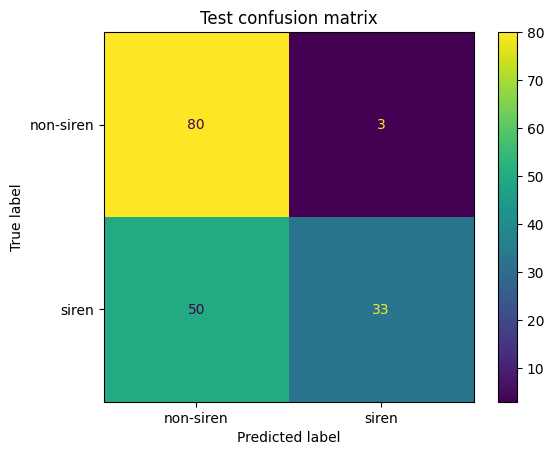

In [26]:
ConfusionMatrixDisplay.from_predictions(
    y_test.astype(int),
    predictions,
    labels=[0, 1],
    display_labels=["non-siren", "siren"],
    values_format="d"
)
plt.title("Test confusion matrix")
plt.show()

## 16. Try one example prediction

The probability is the model's estimated chance that the clip contains a siren. A value of 0.5 or higher is classified as siren.

In [27]:
index = 0

siren_probability = float(
    model.predict(X_test[index:index + 1], verbose=0)[0][0]
)

actual_class = "siren" if y_test[index] == 1 else "non-siren"
predicted_class = "siren" if siren_probability >= 0.5 else "non-siren"

print("Actual class:", actual_class)
print("Predicted class:", predicted_class)
print("Siren probability:", round(siren_probability, 3))

Actual class: non-siren
Predicted class: non-siren
Siren probability: 0.044


## 16. Listen to a test recording

This plays a real recording from the held-out test subset. The printed prediction comes from the CNN, while the actual label comes from the dataset metadata.

In [ ]:
from IPython.display import Audio, display

index = 0

# Show the audio recording used in this test example.
test_row = test_data.iloc[index]
clip_id = test_row["slice_file_name"].replace(".wav", "")
audio, sample_rate = dataset.clip(clip_id).audio

display(Audio(audio, rate=sample_rate))

# Show the model prediction for the same clip.
siren_probability = float(
    model.predict(X_test[index:index + 1], verbose=0)[0][0]
)

actual_class = "siren" if int(test_row["target"]) == 1 else "non-siren"
predicted_class = "siren" if siren_probability >= 0.5 else "non-siren"

print("Actual class:", actual_class)
print("Predicted class:", predicted_class)
print("Siren probability:", round(siren_probability, 3))

## 17. Test your own audio file

You can upload a new `.wav` file and listen to it here. The notebook converts it using the same settings as the training data, then asks the trained model to predict siren or non-siren.

For this simple project, use a short urban sound clip around 4 seconds long. The model is trained on UrbanSound8K, so results on recordings from other sources may be less reliable.

In [ ]:
from google.colab import files

uploaded_files = files.upload()

# Select the first uploaded file.
new_audio_path = next(iter(uploaded_files))
print("Uploaded file:", new_audio_path)

In [ ]:
def prepare_new_audio(file_path):
    # Load as mono audio using the same sample rate as training.
    audio, sample_rate = librosa.load(
        file_path, sr=SAMPLE_RATE, mono=True
    )

    # Pad short clips or trim long clips to four seconds.
    audio = librosa.util.fix_length(audio, size=SAMPLES)

    # Convert the waveform to a mel-spectrogram.
    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=SAMPLE_RATE,
        n_fft=1024,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS
    )
    mel_db = librosa.power_to_db(mel, ref=np.max)

    # Scale it in the same way as the training examples.
    mel_db = ((mel_db + 80) / 80).clip(0, 1)

    # Add batch and channel dimensions for the CNN.
    return mel_db[np.newaxis, ..., np.newaxis], audio

In [ ]:
new_features, new_audio = prepare_new_audio(new_audio_path)

# Play the audio that was uploaded.
display(Audio(new_audio, rate=SAMPLE_RATE))

# Predict whether it contains a siren.
new_probability = float(
    model.predict(new_features, verbose=0)[0][0]
)

if new_probability >= 0.5:
    print("Prediction: SIREN")
else:
    print("Prediction: NON-SIREN")

print("Siren probability:", round(new_probability, 3))

## Conclusion

This mini-project demonstrates a basic audio deep-learning pipeline: load audio, convert it to a mel-spectrogram, train a CNN, evaluate it, listen to test examples, and try a new `.wav` file.

The output is a predicted class, not a generated sound. Audio playback lets you hear the input that the model analyzed.

**Important:** A model prediction is not guaranteed to be correct. The model was trained on a small subset of UrbanSound8K, so it may not generalize well to every recording. Review the [official UrbanSound8K terms](https://urbansounddataset.weebly.com/urbansound8k.html) before using the dataset.